# How does GR and SR affect GPS system?

From the Mercury's orbital precession, we've seen how GR applies on an astronomical scale. Now we can focus on how the same theory influences everyday life - most notably in the operation of the Global Positioning System (GPS).

According to special relativity, time is not absolute: a moving clock ticks more slowly than a stationary one as observed from an external inertial frame (e.g.lab frame). This phenomenon is known as time dilation.
From the perspective of a stationary observer on Earth, the satellite is moving at approximately 3.87km/s. Therefore, the satellite's onboard clock experiences time dilation, and ticks more slowly than a ground-based clock.

According to general relativity, gravity affects the flow of time: the stronger the gravitational field (i.e., the deeper the gravitational potential), the slower time passes. Conversely, in a weaker gravitational field, time runs faster.
A clock at the satellite's position experiences weaker gravity than one on Earth's surface. Therefore, the satellite's clock ticks faster than the clock on Earth.

In [65]:
import numpy as np
import matplotlib.pyplot as plt

In [67]:
G = 6.67430e-11        # gravitational constant unit: m^3 kg^-1 s^-2
M_E = 5.972e24           # mass of Earth  unit: kg
c = 299792458          # speed of light unit: m/s
R_E = 6.371e6          # Earth radius 
R_GPS = 2.66e7         # GPS satellite orbit radius
v = 3.874e3            # GPS satellite orbit velocity unit: m/s

### Time dilation factor dτ/dt:
The ​time dilation factor is crucial in both special relativity and general relativity, because it quantifies how the passage of time changes depending on velocity and gravitational potential.

The time dilation factor is actually decribing how much proper time τ elapses on a local clock (such as a satellite or a ground-based observer) per unit of coordinate time t, which is defined in a shared reference frame. 

What is τ (the proper time)?  
It is the time measured by a clock at rest in its own frame.

What is t (the coordinate time)?  
It is the time measured by an observer in a shared global reference frame. 
In the GPS system, this reference frame is typically the Earth-centered inertial (ECI) frame, which is a non-rotating coordinate system centered at the Earth's center of mass and fixed relative to the distant stars.

## GR effect:
In a weak gravitational field, the time dilation factor is approximately:  
$$
\text{Time Dilation Factor} = \frac{d\tau}{dt} \approx 1 - \frac{GM}{rc^2}
$$ 
What we should focus on is the amount of proper time that has elapsed on different clocks (e.g., one on a satellite and one on Earth) over the same interval of coordinate time t because coordinate time serves as the common baseline for synchronization in the GPS system.)   
The ground-based clock accumulates proper time:
$$
\tau_{\text{E}} = \left( \frac{d\tau}{dt} \Big|_{\text{E}} \right) \cdot t
$$  
The satellite clock accumulates proper time:
$$
\tau_{\text{GPS}} = \left( \frac{d\tau}{dt} \Big|_{\text{GPS}} \right) \cdot t
$$  
Therefore, the difference in proper time between the two clocks over the same coordinate time interval is:
$$
\Delta \tau = \left( \frac{d\tau}{dt} \Big|_{\text{GPS}} - \frac{d\tau}{dt} \Big|_{\text{E}} \right) \cdot t
$$


In [71]:
def time_dilation(r):
    return 1 - (G * M_E) / (r * c**2)

tau_E = time_dilation(R_E)
tau_GPS = time_dilation(R_GPS)

# In ECI frame, 1 day = 24 * 60 * 60
delta_GR = (tau_GPS - tau_E) * 24 * 60 * 60 
delta_GR_us = delta_GR * 1e6  #Convert time difference from s to us

print(f"GR time gain of GPS satellite over ground: {delta_GR_us:.2f} μs/day")

GR time gain of GPS satellite over ground: 45.74 μs/day


### SR effect:
In special relativity, the time dilation factor is given by:
$$
\frac{d\tau}{dt} = \sqrt{1 - \frac{v^2}{c^2}}
$$  
v here is the velocity of the satellite.

In [77]:
SR_factor = 1 - v**2 / (2 * c**2)  #1/gamma
ratio = SR_factor

delta_SR = (ratio - 1) * 24 * 60 * 60
delta_SR_us = delta_SR * 1e6

print(f"SR time loss of GPS satellite due to motion: {delta_SR_us:.2f} μs/day")

SR time loss of GPS satellite due to motion: -7.21 μs/day


In [79]:
delta_total = delta_GR_us + delta_SR_us
print(f"Net time difference between the satellite clock and the ground clock: {delta_total:.2f} μs/day")

Net time difference between the satellite clock and the ground clock: 38.52 μs/day


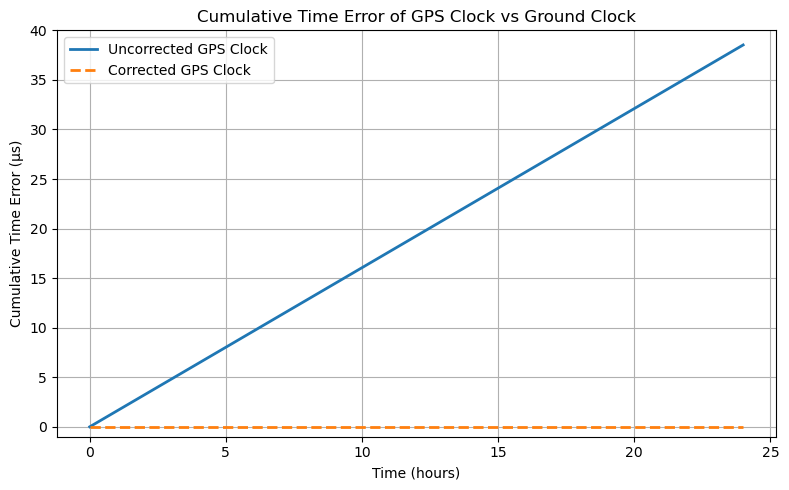

In [81]:
hours = np.linspace(0, 24, 500)
seconds = hours * 3600

delta_us_per_day = delta_total
delta_us_per_sec = delta_us_per_day / (24 * 3600)

gps_error = delta_us_per_sec * seconds
corrected_clock = np.zeros_like(seconds)

plt.figure(figsize=(8, 5))
plt.plot(hours, gps_error, label="Uncorrected GPS Clock", linewidth=2)
plt.plot(hours, corrected_clock, label="Corrected GPS Clock", linestyle='--', linewidth=2)
plt.xlabel("Time (hours)")
plt.ylabel("Cumulative Time Error (μs)")
plt.title("Cumulative Time Error of GPS Clock vs Ground Clock")
plt.legend()
plt.grid(True)
plt.ylim(-1, 40)  
plt.tight_layout()
plt.show()

### Why does this 38 μs/day time difference matter?
GPS works by measuring the time it takes for signals to travel from multiple satellites to a receiver on Earth. Since these signals travel at the speed of light (approximately 
$3\times10^2$meters per second), even a tiny error in time leads to a large error in distance.  
A 38 μs error would lead to a cumulative positioning error over 11km per day -- The GPS system becomes completely unusable for precise navigation!
Relativistic time correction is always applied to the GPS system.